In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import math
import numpy as np


In [2]:
from pdm.data import load_cmapss, load_rul

train = load_cmapss("FD001", "train")
test = load_cmapss("FD001", "test")
rul = load_rul("FD001")

In [3]:
train["cycles_before_failure"] = train["cycle"] - train.groupby("unit")["cycle"].transform("max")

In [4]:
train['cycles_before_failure']

0       -191
1       -190
2       -189
3       -188
4       -187
        ... 
20626     -4
20627     -3
20628     -2
20629     -1
20630      0
Name: cycles_before_failure, Length: 20631, dtype: int64

In [5]:
train.drop(columns=['sensor_1','setting_3','sensor_10','sensor_18','sensor_19','sensor_16','sensor_5'],inplace=True)

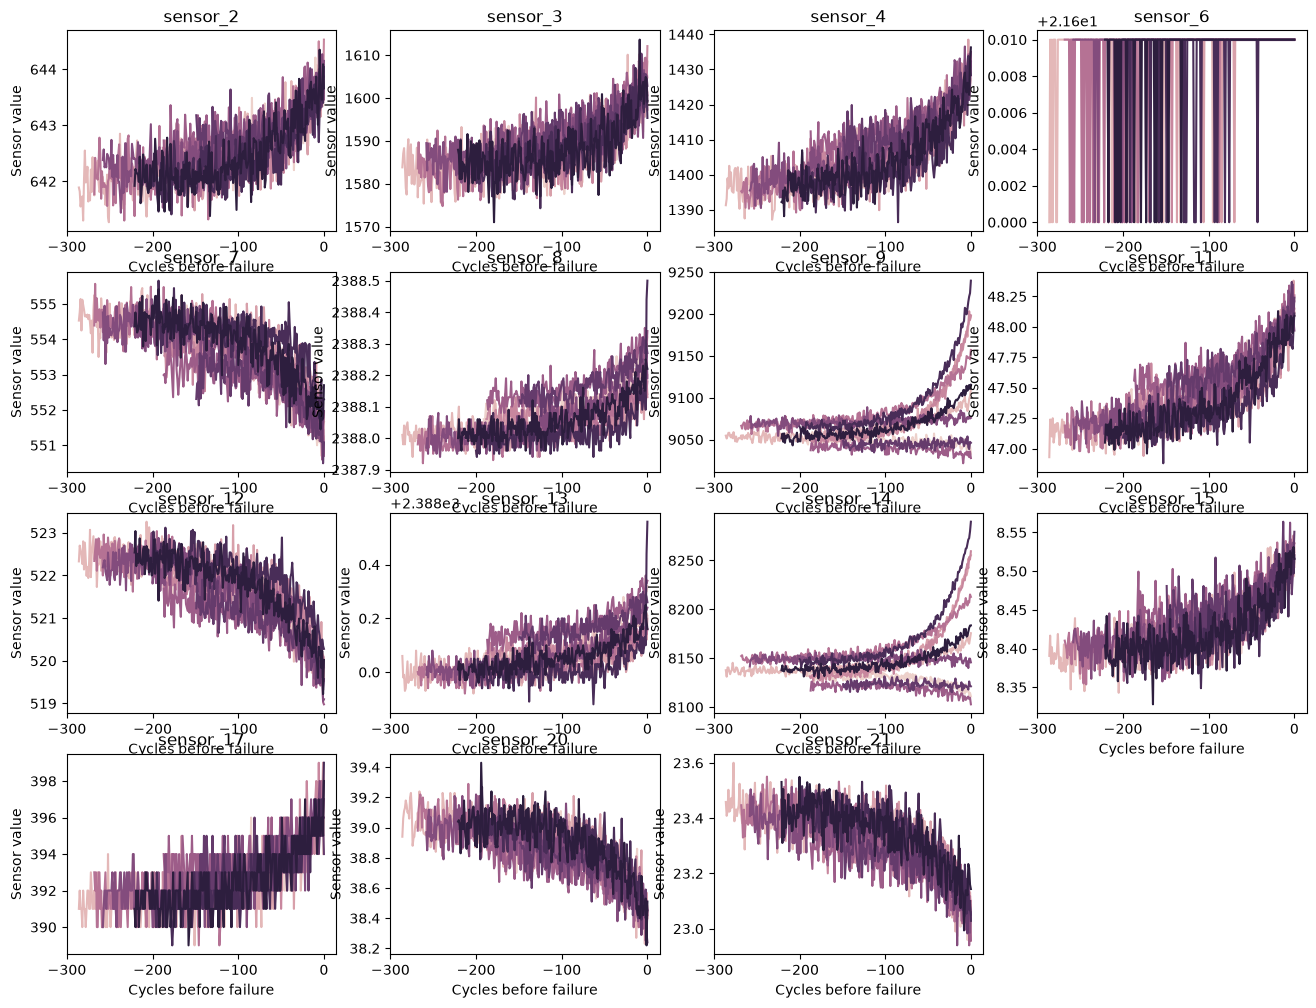

In [8]:
sensor_cols = [col for col in train.columns if col.startswith("sensor_")]

#choosing 10 engines
engines = train["unit"].unique()[:10]
data = train[train["unit"].isin(engines)]

n_cols = 4
n_rows = math.ceil(len(sensor_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(16, 3 * n_rows)
)

axes = axes.flatten() #to loop through the plots

for i, sensor in enumerate(sensor_cols):
    sns.lineplot(
        data=data,
        x="cycles_before_failure",
        y=sensor,
        hue="unit",
        ax=axes[i],
        legend=False
    )
    axes[i].set_title(sensor)
    axes[i].set_xlabel("Cycles before failure")
    axes[i].set_ylabel("Sensor value")
    
# Remove unused subplots
for j in range(len(sensor_cols), len(axes)):
    fig.delaxes(axes[j])
    
plt.show()

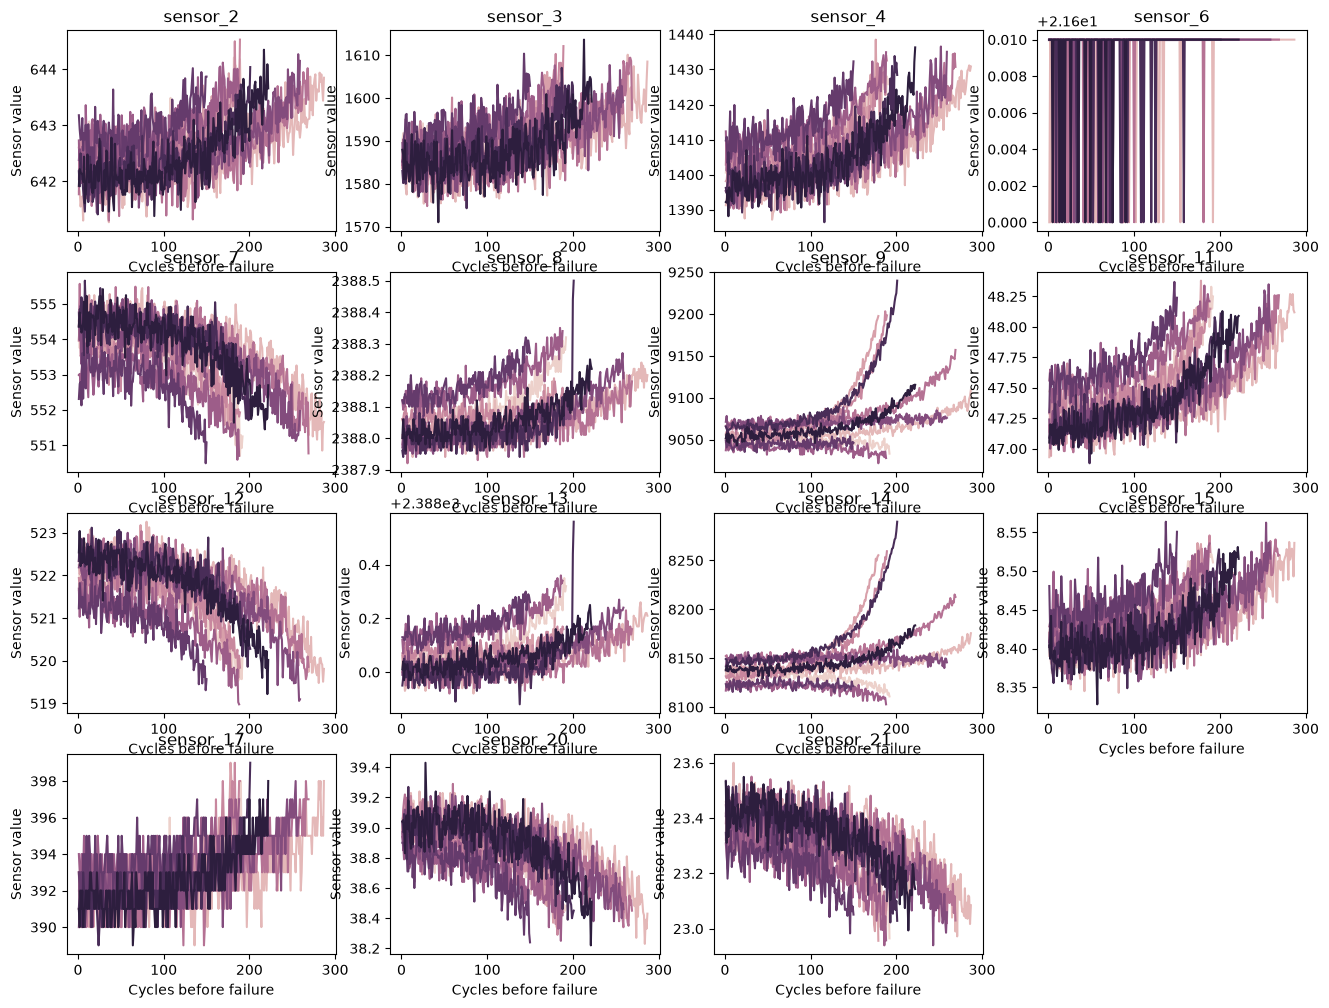

In [ ]:
sensor_cols = [col for col in train.columns if col.startswith("sensor_")]

#choosing 10 engines
engines = train["unit"].unique()[:10]
data = train[train["unit"].isin(engines)]

n_cols = 4
n_rows = math.ceil(len(sensor_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols, figsize=(16, 3 * n_rows)
)

axes = axes.flatten() #to loop through the plots

for i, sensor in enumerate(sensor_cols):
    sns.lineplot(
        data=data,
        x="cycle",
        y=sensor,
        hue="unit",
        ax=axes[i],
        legend=False
    )
    axes[i].set_title(sensor)
    axes[i].set_xlabel("Cycles")
    axes[i].set_ylabel("Sensor value")
    
# Remove unused subplots
for j in range(len(sensor_cols), len(axes)):
    fig.delaxes(axes[j])
    
plt.show()

| Sensor | Trend near failure (↑ / ↓ / none) | Noise (low / med / high) | Keep as candidate? |

| sensor_2 | ↑ | high | Yes |
| sensor_3 | ↑ | high | Yes |
| sensor_4 | ↑ | high | Yes |
| sensor_6 | None | high | No |
| sensor_7 | ↓ | high | Yes |
| sensor_8 | ↑ | high | Yes |
| sensor_9 | none | med | Yes |
| sensor_11 | ↑ | high | Yes |
| sensor_12 | ↓ | high | Yes |
| sensor_13 | ↑ | high | Yes |
| sensor_14 | none | med | Yes |
| sensor_15 | ↑ | high | Yes |
| sensor_17 | ↑ | high | Yes |
| sensor_20 | ↓ | high | Yes |
| sensor_21 | ↓ | high | Yes |


In [12]:
#correlation
corr_matrix=train[sensor_cols].corr()
corr_matrix

,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
sensor_2,1.000000,0.602610,0.714949,0.132242,-0.702136,0.662325,0.273764,0.740020,-0.724578,0.661792,0.179752,0.675975,0.629886,-0.661841,-0.668050
sensor_3,0.602610,1.000000,0.678413,0.116039,-0.664595,0.602481,0.322964,0.695900,-0.680307,0.600963,0.237137,0.639921,0.600017,-0.625941,-0.633901
sensor_4,0.714949,0.678413,1.000000,0.150480,-0.793130,0.746852,0.297429,0.830136,-0.815591,0.745158,0.190748,0.758459,0.703499,-0.748067,-0.745193
sensor_6,0.132242,0.116039,0.150480,1.000000,-0.155720,0.152161,0.019347,0.160014,-0.155884,0.158276,-0.002112,0.149042,0.130810,-0.141419,-0.137419
sensor_7,-0.702136,-0.664595,-0.793130,-0.155720,1.000000,-0.767132,-0.217835,-0.822805,0.812713,-0.764611,-0.110053,-0.747051,-0.692893,0.736163,0.737447
sensor_8,0.662325,0.602481,0.746852,0.152161,-0.767132,1.000000,-0.032091,0.782213,-0.786540,0.826084,-0.144787,0.700949,0.627785,-0.687030,-0.688840
sensor_9,0.273764,0.322964,0.297429,0.019347,-0.217835,-0.032091,1.000000,0.274591,-0.210238,-0.034763,0.963157,0.293753,0.337110,-0.285280,-0.292795
sensor_11,0.740020,0.695900,0.830136,0.160014,-0.822805,0.782213,0.274591,1.000000,-0.846884,0.780761,0.163408,0.780913,0.722296,-0.771510,-0.772554
sensor_12,-0.724578,-0.680307,-0.815591,-0.155884,0.812713,-0.786540,-0.210238,-0.846884,1.000000,-0.788441,-0.098141,-0.766052,-0.703485,0.751943,0.756263
sensor_13,0.661792,0.600963,0.745158,0.158276,-0.764611,0.826084,-0.034763,0.780761,-0.788441,1.000000,-0.147036,0.697662,0.627410,-0.686172,-0.688948


<Axes: >

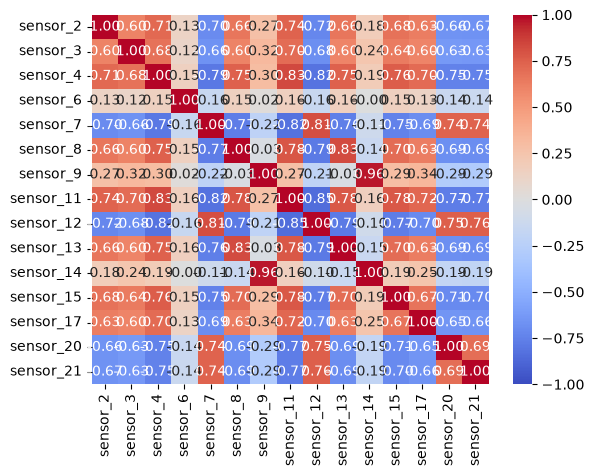

In [16]:
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)

In [17]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
pairs = upper.stack()
pairs[pairs.abs() > 0.9]

sensor_9  sensor_14    0.963157
dtype: float64

### Findings: Sensor Correlation and Redundancy

- **Strong redundancy:** `sensor_9` and `sensor_14` have a correlation of 0.96, indicating a very strong positive linear relationship and potentially overlapping information.
- **Different degradation behavior:** Despite their high correlation, `sensor_9` and `sensor_14` increase in only 71% and 60% of engines, respectively. Their trends are therefore not consistent across all engines, providing another reason to test models with and without `sensor_14`.
- **Potential redundancy:** `sensor_11` and `sensor_12` have a correlation of 0.85, suggesting a substantial relationship, although this alone does not justify removing either sensor.
- **Limited high correlation:** Only one sensor pair has an absolute correlation above 0.9, so most candidate sensors do not exhibit extremely strong pairwise linear correlations.
- **Opposite degradation trends:** Sensors 7, 12, 20, and 21 decrease as the engine approaches failure, while other sensors tend to increase. These opposing trends can explain negative correlations, which still indicate strong relationships when their absolute values are high.
- **Sensor noise:** Most sensors fluctuate considerably from cycle to cycle, suggesting that individual measurements may be unreliable indicators of degradation. Smoothing or rolling averages could help reveal underlying trends, provided they do not obscure important changes near failure.